# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Ahmad Dhafin Al Farisy
- **Email:** ahmad.dhafin.al-2024@fst.unair.ac.id
- **ID Dicoding:** ahmdhafin

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (revenue) tertinggi dan terendah sepanjang tahun 2017?
- **Pertanyaan 2:** Bagaimana pengaruh keterlambatan pengiriman terhadap rata-rata skor ulasan (review score) pesanan pelanggan sepanjang periode 2017 hingga 2018?

## Import Semua Packages/Library yang Digunakan

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load Seluruh Dataset E-Commerce (customers_df, orders_df, order_items_df, products_df, dll.)

In [29]:
customers_df = pd.read_csv("customers_dataset.csv")
geolocation_df = pd.read_csv("geolocation_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
order_payments_df = pd.read_csv("order_payments_dataset.csv")
order_reviews_df = pd.read_csv("order_reviews_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
category_trans_df = pd.read_csv("product_category_name_translation.csv")
products_df = pd.read_csv("products_dataset.csv")
sellers_df = pd.read_csv("sellers_dataset.csv")

# Menampilkan 5 baris pertama dari tabel orders untuk memastikan data berhasil dimuat
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** Kesembilan tabel dari E-Commerce Public Dataset telah berhasil dimuat ke dalam DataFrame dan siap untuk diperiksa kualitasnya pada tahap Assessing Data.

### Assessing Data

#### Menilai Kualitas Seluruh Tabel Dataset E-Commerce

In [30]:
datasets = {
    "customers": customers_df,
    "geolocation": geolocation_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "orders": orders_df,
    "category_trans": category_trans_df,
    "products": products_df,
    "sellers": sellers_df
}

for name, df in datasets.items():
    print(f"================ {name.upper()} ================")
    df.info()
    print("\nJumlah Missing Value:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print(f"\nJumlah Duplikasi: {df.duplicated().sum()}\n")

================ CUSTOMERS ================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Jumlah Missing Value:
Series([], dtype: int64)

Jumlah Duplikasi: 0

================ GEOLOCATION ================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geoloca

**Steps to Take:**
- Mengubah tipe data kolom tanggal yang masih bertipe `object` menjadi `datetime` pada tabel `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`), `order_items_df` (`shipping_limit_date`), dan `order_reviews_df` (`review_creation_date`, `review_answer_timestamp`).
- Menangani *missing value* pada `products_df` dengan mengisi 610 nilai kosong pada kolom `product_category_name` menjadi `"unknown"`, serta mengisi 2 nilai kosong pada dimensi/berat produk menggunakan nilai median.
- Menangani *missing value* pada `orders_df` (kolom waktu persetujuan dan pengiriman yang kosong karena pesanan dibatalkan/belum terkirim) dengan cara memfilter data hanya pada pesanan berstatus `delivered` saat melakukan analisis transaksi.
- Menangani *missing value* pada `order_reviews_df` (`review_comment_title` dan `review_comment_message`) dengan mengisinya menjadi `"No comment"` (atau mengabaikannya jika tidak menganalisis teks ulasan).
- Menghapus 261.831 data duplikat pada `geolocation_df` menggunakan `drop_duplicates()` apabila tabel ini digunakan.

**Insight:**
- Sebagian besar tabel utama (`customers`, `order_items`, `order_payments`, `category_trans`, `sellers`) sudah bersih dari *missing value* maupun duplikasi data.
- Permasalahan utama pada dataset ini terletak pada ketidaksesuaian tipe data waktu (`object` alih-alih `datetime`), adanya 610 produk tanpa nama kategori pada `products_df`, serta adanya duplikasi massal (261.831 baris) pada `geolocation_df`.

### Cleaning Data

#### Membersihkan Tipe Data Waktu, Missing Value, dan Duplikasi Data

In [31]:
# 1. Mengubah tipe data tanggal menjadi datetime
datetime_orders = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])

# 2. Menangani missing value pada products_df
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
num_cols = [
    "product_name_lenght", "product_description_lenght", "product_photos_qty",
    "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"
]
for col in num_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# 3. Menangani missing value pada order_reviews_df
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No comment")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No comment")

# 4. Menghapus duplikasi pada geolocation_df
geolocation_df.drop_duplicates(inplace=True)

# 5. Verifikasi hasil pembersihan
print("Missing value products_df:", products_df.isna().sum().sum())
print("Missing value order_reviews_df:", order_reviews_df.isna().sum().sum())
print("Duplikat geolocation_df:", geolocation_df.duplicated().sum())
print("\nTipe data orders_df:")
print(orders_df.dtypes)

Missing value products_df: 0
Missing value order_reviews_df: 0
Duplikat geolocation_df: 0

Tipe data orders_df:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:**
- Nilai *missing value* pada tabel `products_df` dan `order_reviews_df` berhasil ditangani hingga tersisa `0` *missing value* pada kedua tabel tersebut.
- Seluruh data duplikat pada tabel `geolocation_df` telah berhasil dihapus sehingga jumlah duplikasi kini menjadi `0`.
- Kelima kolom waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) telah berhasil dikonversi menjadi tipe data `datetime64[ns]` dan siap digunakan untuk tahap eksplorasi data.

## Exploratory Data Analysis (EDA)

### Eksplorasi Pendapatan Kategori Produk, Tren Pesanan, dan Ketepatan Pengiriman

In [32]:
# 1. Menggabungkan produk dengan terjemahan bahasa Inggrisnya
products_english_df = pd.merge(
    left=products_df,
    right=category_trans_df,
    how="left",
    on="product_category_name"
)
products_english_df["product_category_name_english"] = products_english_df["product_category_name_english"].fillna(
    products_english_df["product_category_name"]
)

# 2. Menggabungkan tabel utama (orders, customers, order_items, products)
all_df = pd.merge(orders_df, customers_df, on="customer_id", how="left")
all_df = pd.merge(all_df, order_items_df, on="order_id", how="left")
all_df = pd.merge(all_df, products_english_df, on="product_id", how="left")

# 3. Filter hanya pesanan yang berstatus 'delivered' agar perhitungan akurat
delivered_df = all_df[all_df["order_status"] == "delivered"].copy()

# 4. Eksplorasi 1: Total pendapatan (revenue) dan jumlah item terjual per kategori
category_revenue = delivered_df.groupby("product_category_name_english").agg(
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    total_revenue=("price", "sum")
).reset_index()

print("=== TOP 5 KATEGORI PENDAPATAN TERTINGGI ===")
print(category_revenue.sort_values(by="total_revenue", ascending=False).head(5))

print("\n=== TOP 5 KATEGORI PENDAPATAN TERENDAH ===")
print(category_revenue.sort_values(by="total_revenue", ascending=True).head(5))

# 5. Eksplorasi 2: Tren jumlah pesanan per bulan (Januari 2017 - Agustus 2018)
delivered_df["year_month"] = delivered_df["order_purchase_timestamp"].dt.to_period("M")
monthly_orders = delivered_df.groupby("year_month").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

monthly_2017_2018 = monthly_orders[monthly_orders["year_month"] >= "2017-01"]
print("\n=== TREN PESANAN BULANAN (2017 - 2018) ===")
print(monthly_2017_2018)

=== TOP 5 KATEGORI PENDAPATAN TERTINGGI ===
   product_category_name_english  total_orders  total_items  total_revenue
43                 health_beauty          8647         9465     1233131.72
73                 watches_gifts          5495         5859     1166176.98
7                 bed_bath_table          9272        10953     1023434.76
67                sports_leisure          7530         8431      954852.55
15         computers_accessories          6530         7644      888724.61

=== TOP 5 KATEGORI PENDAPATAN TERENDAH ===
   product_category_name_english  total_orders  total_items  total_revenue
63         security_and_services             2            2         283.29
29     fashion_childrens_clothes             7            7         519.95
11             cds_dvds_musicals            12           14         730.00
46                home_comfort_2            24           30         760.27
35                       flowers            29           33        1110.04

=== TREN PE

**Insight:**
- **Performa Kategori Produk (Pendapatan):** Kategori **`health_beauty`** menjadi penyumbang pendapatan terbesar dengan total **`1.233.131,72`** (dari 8.647 pesanan / 9.465 item), diikuti oleh **`watches_gifts`** (`1.166.176,98`) dan **`bed_bath_table`** (`1.023.434,76`). Sebaliknya, kategori dengan pendapatan terendah adalah **`security_and_services`** yang hanya menghasilkan **`283,29`** dari 2 pesanan.
- **Volume Pesanan vs Nilai Transaksi:** Meskipun kategori `bed_bath_table` memiliki volume pesanan tertinggi (9.272 pesanan), total pendapatannya masih berada di bawah `health_beauty` dan `watches_gifts` karena harga satuan rata-rata produknya lebih rendah.
- **Tren Pesanan Bulanan (2017–2018):** Jumlah pesanan mengalami pertumbuhan pesat sepanjang tahun 2017 (naik dari **750 pesanan** pada Januari 2017) dan mencapai puncaknya pada **November 2017** dengan **`7.289` pesanan** (total pendapatan `987.765,37`). Pada tahun 2018 (Januari–Agustus), performa transaksi cenderung stabil di kisaran **6.000 hingga 7.000 pesanan** per bulan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total pendapatan (revenue) tertinggi dan terendah sepanjang tahun 2017?

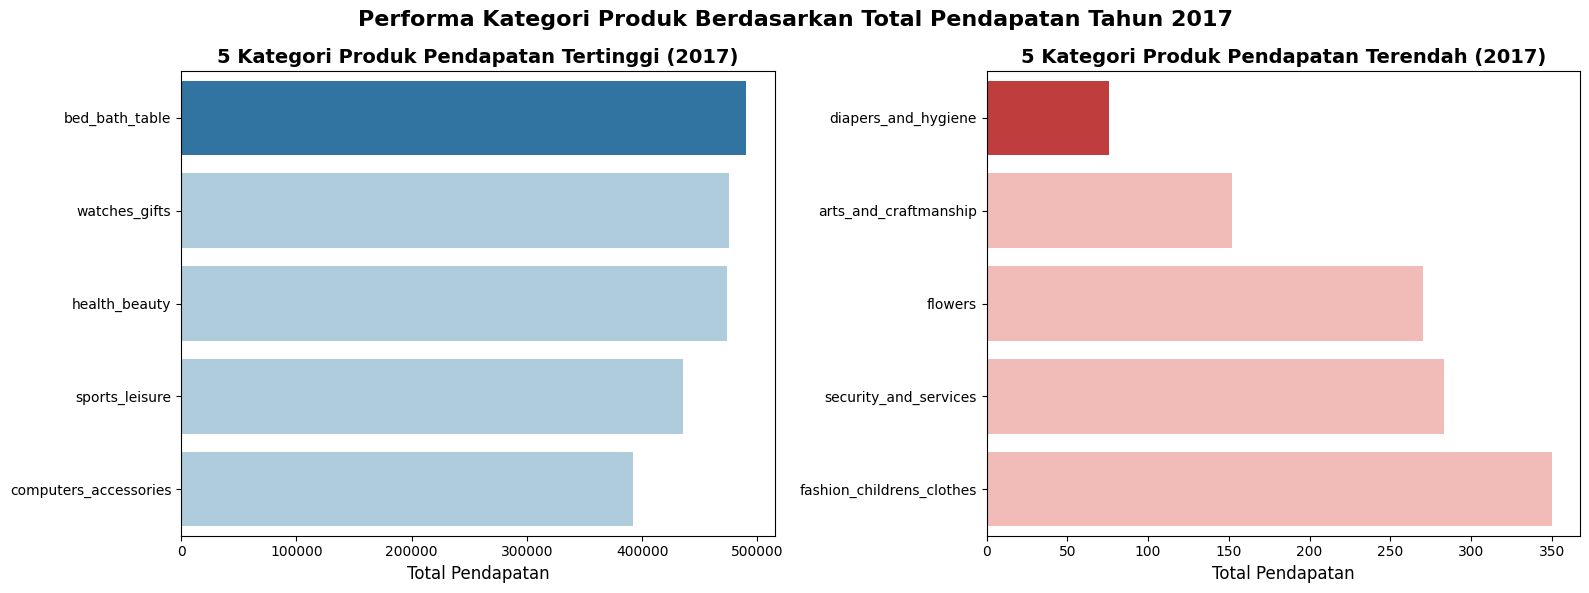

Top 5 2017:
    product_category_name_english  total_revenue
7                 bed_bath_table      490596.92
72                 watches_gifts      475610.71
43                 health_beauty      473833.00
66                sports_leisure      435674.14
15         computers_accessories      391786.29

Bottom 5 2017:
    product_category_name_english  total_revenue
23           diapers_and_hygiene          76.00
3          arts_and_craftmanship         151.89
35                       flowers         270.50
62         security_and_services         283.29
29     fashion_childrens_clothes         349.98


In [33]:
# Filter data transaksi delivered khusus tahun 2017
df_2017 = delivered_df[delivered_df["order_purchase_timestamp"].dt.year == 2017]

# Hitung total revenue per kategori di tahun 2017
cat_rev_2017 = df_2017.groupby("product_category_name_english")["price"].sum().reset_index()
cat_rev_2017.rename(columns={"price": "total_revenue"}, inplace=True)

top_5_2017 = cat_rev_2017.sort_values(by="total_revenue", ascending=False).head(5)
bottom_5_2017 = cat_rev_2017.sort_values(by="total_revenue", ascending=True).head(5)

# Membuat visualisasi berdampingan (Top 5 vs Bottom 5)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Warna sorotan (highlight) pada bar tertinggi & terendah sesuai prinsip desain visualisasi
colors_top = ["#1f77b4", "#a6cee3", "#a6cee3", "#a6cee3", "#a6cee3"]
colors_bottom = ["#d62728", "#fbb4ae", "#fbb4ae", "#fbb4ae", "#fbb4ae"]

sns.barplot(x="total_revenue", y="product_category_name_english", data=top_5_2017, palette=colors_top, hue="product_category_name_english", legend=False, ax=ax[0])
ax[0].set_title("5 Kategori Produk Pendapatan Tertinggi (2017)", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Total Pendapatan", fontsize=12)
ax[0].set_ylabel(None)

sns.barplot(x="total_revenue", y="product_category_name_english", data=bottom_5_2017, palette=colors_bottom, hue="product_category_name_english", legend=False, ax=ax[1])
ax[1].set_title("5 Kategori Produk Pendapatan Terendah (2017)", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Total Pendapatan", fontsize=12)
ax[1].set_ylabel(None)

plt.suptitle("Performa Kategori Produk Berdasarkan Total Pendapatan Tahun 2017", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# Menampilkan angka pastinya untuk memudahkan penulisan Insight
print("Top 5 2017:\n", top_5_2017)
print("\nBottom 5 2017:\n", bottom_5_2017)

### Pertanyaan 2: Bagaimana pengaruh keterlambatan pengiriman terhadap rata-rata skor ulasan (review score) pesanan pelanggan sepanjang periode 2017 hingga 2018?

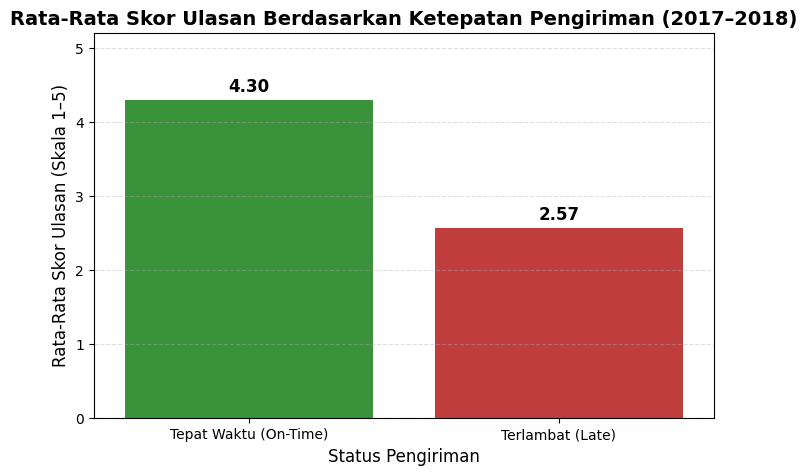

         delivery_status  total_orders  avg_review_score
0  Tepat Waktu (On-Time)         87902          4.295086
1       Terlambat (Late)          7658          2.566728


In [34]:
# Mengambil pesanan delivered unik (per order_id) periode 2017 - 2018
orders_unique = delivered_df[["order_id", "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]].drop_duplicates()
orders_17_18 = orders_unique[orders_unique["order_purchase_timestamp"].dt.year.isin([2017, 2018])].copy()

# Gabungkan dengan data review (ambil rata-rata skor jika 1 order punya >1 review)
reviews_clean = order_reviews_df.groupby("order_id")["review_score"].mean().reset_index()
delivery_review_df = pd.merge(orders_17_18, reviews_clean, on="order_id", how="inner")

# Hapus baris jika tanggal pengiriman aktual kosong
delivery_review_df.dropna(subset=["order_delivered_customer_date"], inplace=True)

# Tentukan status pengiriman: Terlambat jika tanggal sampai > tanggal estimasi
delivery_review_df["delivery_status"] = np.where(
    delivery_review_df["order_delivered_customer_date"] > delivery_review_df["order_estimated_delivery_date"],
    "Terlambat (Late)",
    "Tepat Waktu (On-Time)"
)

# Hitung rata-rata skor ulasan berdasarkan status pengiriman
review_summary = delivery_review_df.groupby("delivery_status").agg(
    total_orders=("order_id", "count"),
    avg_review_score=("review_score", "mean")
).reset_index()

# Membuat visualisasi Bar Chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x="delivery_status",
    y="avg_review_score",
    data=review_summary,
    palette=["#2ca02c", "#d62728"],
    hue="delivery_status",
    legend=False
)

# Menambahkan label angka tepat di atas batang grafik
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=12, fontweight="bold", padding=3)

plt.title("Rata-Rata Skor Ulasan Berdasarkan Ketepatan Pengiriman (2017–2018)", fontsize=14, fontweight="bold")
plt.xlabel("Status Pengiriman", fontsize=12)
plt.ylabel("Rata-Rata Skor Ulasan (Skala 1–5)", fontsize=12)
plt.ylim(0, 5.2)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

print(review_summary)

**Insight:**
- **Kategori Produk Pendapatan Tertinggi & Terendah (2017):** Sepanjang tahun 2017, kategori **`bed_bath_table`** menghasilkan total pendapatan tertinggi sebesar **`490.596,92`**, diikuti ketat oleh **`watches_gifts`** (`475.610,71`) dan **`health_beauty`** (`473.833,00`). Sebaliknya, kategori dengan pendapatan terendah di tahun 2017 adalah **`diapers_and_hygiene`** yang hanya mencatat total pendapatan **`76,00`**, diikuti oleh **`arts_and_craftmanship`** (`151,89`).
- **Pengaruh Keterlambatan Pengiriman terhadap Skor Ulasan (2017–2018):** Ketepatan waktu pengiriman terbukti sangat memengaruhi tingkat kepuasan pelanggan. Pesanan yang tiba **Tepat Waktu (*On-Time*)** (87.902 pesanan) memperoleh rata-rata skor ulasan tinggi sebesar **`4,30`** (skala 1–5), sedangkan pesanan yang **Terlambat (*Late*)** (7.658 pesanan) mengalami penurunan skor ulasan yang sangat tajam hingga rata-rata **`2,57`** (turun sekitar 1,73 poin).

## Analisis Lanjutan (Opsional)

**Tujuan Analisis Lanjutan (RFM Analysis):**
Analisis RFM (*Recency, Frequency, Monetary*) dilakukan untuk mengelompokkan pelanggan berdasarkan perilaku transaksi mereka tanpa menggunakan *machine learning*, dengan mengukur tiga parameter utama:
- **Recency:** Jumlah hari sejak terakhir kali pelanggan melakukan transaksi (diukur dari tanggal transaksi terakhir di dataset).
- **Frequency:** Total jumlah pesanan (*order*) unik yang dilakukan oleh masing-masing pelanggan.
- **Monetary:** Total pengeluaran (pendapatan) yang dihasilkan oleh masing-masing pelanggan.

=== RINGKASAN STATISTIK RFM ===
            recency     frequency      monetary
count  93358.000000  93358.000000  93358.000000
mean     236.941773      1.033420    141.621480
std      152.591453      0.209097    215.694014
min        0.000000      1.000000      0.850000
25%      113.000000      1.000000     47.650000
50%      218.000000      1.000000     89.730000
75%      345.000000      1.000000    154.737500
max      713.000000     15.000000  13440.000000


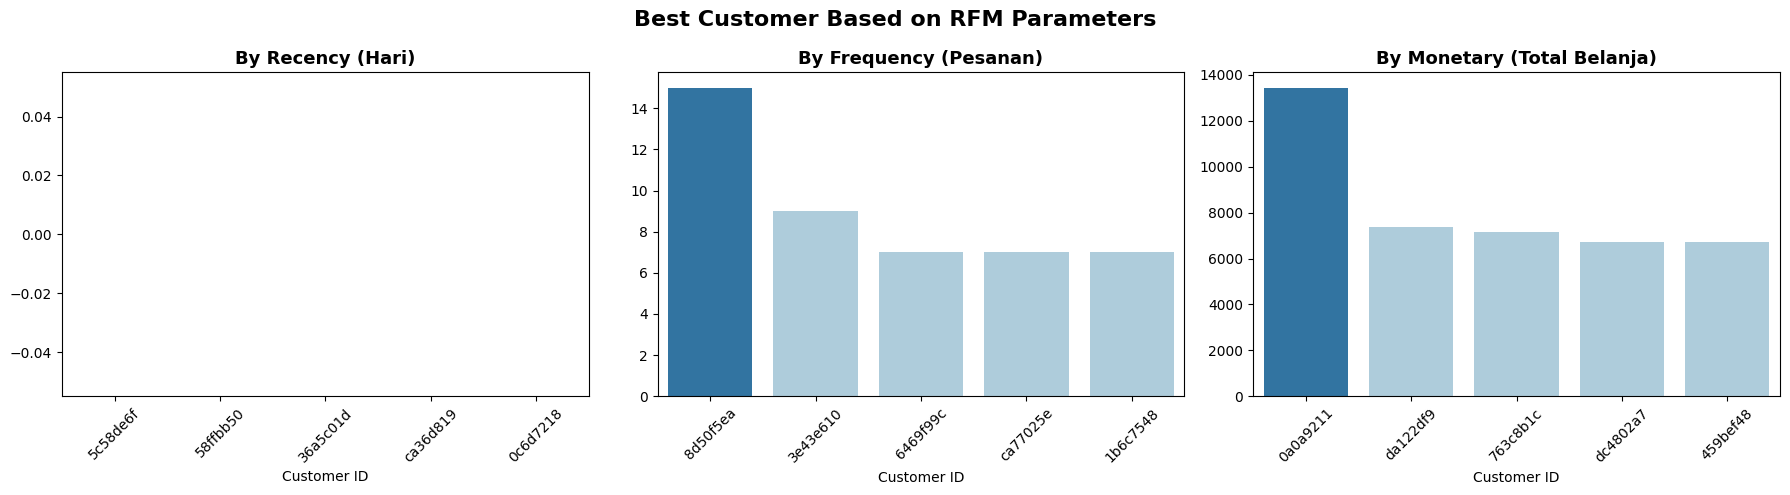

In [35]:
# 1. Menghitung nilai Recency, Frequency, dan Monetary per pelanggan unik
rfm_df = delivered_df.groupby(by="customer_unique_id", as_index=False).agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)

# Menghitung Recency (dalam hari) relatif terhadap tanggal transaksi terakhir di dataset
recent_date = delivered_df["order_purchase_timestamp"].max()
rfm_df["recency"] = (recent_date - rfm_df["max_order_timestamp"]).dt.days
rfm_df.drop("max_order_timestamp", axis=1, inplace=True)

# Buat ID pendek (8 karakter awal) agar label sumbu X pada grafik rapi dan terbaca
rfm_df["short_id"] = rfm_df["customer_unique_id"].str[:8]

# 2. Menampilkan ringkasan statistik RFM
print("=== RINGKASAN STATISTIK RFM ===")
print(rfm_df[["recency", "frequency", "monetary"]].describe())

# 3. Visualisasi Top 5 Pelanggan Terbaik berdasarkan R, F, dan M
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
colors = ["#1f77b4", "#a6cee3", "#a6cee3", "#a6cee3", "#a6cee3"]

# By Recency (semakin kecil hari semakin baik)
top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5)
sns.barplot(y="recency", x="short_id", data=top_recency, palette=colors, hue="short_id", legend=False, ax=ax[0])
ax[0].set_title("By Recency (Hari)", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Customer ID")
ax[0].set_ylabel(None)
ax[0].tick_params(axis="x", rotation=45)

# By Frequency (semakin sering semakin baik)
top_frequency = rfm_df.sort_values(by="frequency", ascending=False).head(5)
sns.barplot(y="frequency", x="short_id", data=top_frequency, palette=colors, hue="short_id", legend=False, ax=ax[1])
ax[1].set_title("By Frequency (Pesanan)", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Customer ID")
ax[1].set_ylabel(None)
ax[1].tick_params(axis="x", rotation=45)

# By Monetary (semakin besar belanja semakin baik)
top_monetary = rfm_df.sort_values(by="monetary", ascending=False).head(5)
sns.barplot(y="monetary", x="short_id", data=top_monetary, palette=colors, hue="short_id", legend=False, ax=ax[2])
ax[2].set_title("By Monetary (Total Belanja)", fontsize=13, fontweight="bold")
ax[2].set_xlabel("Customer ID")
ax[2].set_ylabel(None)
ax[2].tick_params(axis="x", rotation=45)

plt.suptitle("Best Customer Based on RFM Parameters", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- **Recency (Keterbaruan Transaksi):** Dari total **93.358 pelanggan unik**, rata-rata pelanggan terakhir kali berbelanja sekitar **237 hari** sebelum tanggal transaksi terakhir di dataset (nilai tengah/median **218 hari**). Pelanggan teratas pada grafik *By Recency* (`5c58de6f`, `58ffbb50`, dll.) memiliki nilai `0` hari karena baru saja melakukan transaksi pada hari terakhir periode pencatatan.
- **Frequency (Frekuensi Pembelian):** Mayoritas besar pelanggan (lebih dari 75% pelanggan) hanya melakukan **1 kali transaksi** dengan rata-rata frekuensi **1,03 kali**, sedangkan pelanggan paling loyal (`8d50f5ea`) tercatat melakukan hingga **15 kali pesanan**.
- **Monetary (Total Pengeluaran):** Rata-rata pengeluaran per pelanggan berada di angka **`141,62`** (median **`89,73`**), sementara pelanggan dengan nilai belanja tertinggi (`0a0a9211`) mencatatkan total pengeluaran sebesar **`13.440,00`**.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang tahun 2017, kategori produk yang menghasilkan total pendapatan (*revenue*) tertinggi adalah **`bed_bath_table`** sebesar **`490.596,92`**, diikuti oleh **`watches_gifts`** (`475.610,71`) dan **`health_beauty`** (`473.833,00`). Sebaliknya, kategori produk dengan total pendapatan terendah adalah **`diapers_and_hygiene`** sebesar **`76,00`**, diikuti oleh **`arts_and_craftmanship`** (`151,89`).
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman terbukti memberikan dampak negatif yang sangat signifikan terhadap kepuasan pelanggan sepanjang periode 2017–2018. Pesanan yang dikirim **Tepat Waktu (*On-Time*)** mencatat rata-rata skor ulasan sebesar **`4,30`**, sedangkan pesanan yang **Terlambat (*Late*)** anjlok hingga rata-rata skor **`2,57`** (selisih penurunan sebesar 1,73 poin).

**Rekomendasi Action Item:**
- **Optimasi Stok & Promosi Kategori Unggulan:** Memprioritaskan ketersediaan stok dan anggaran kampanye pemasaran pada kategori penyumbang pendapatan terbesar (`bed_bath_table`, `watches_gifts`, dan `health_beauty`), sekaligus mengevaluasi kembali visibilitas atau efisiensi katalog pada kategori berpendapatan sangat rendah seperti `diapers_and_hygiene`.
- **Perbaikan Performa Logistik & Estimasi Pengiriman:** Mengevaluasi mitra logistik pada rute atau penjual dengan tingkat keterlambatan tinggi serta memperbarui algoritma estimasi waktu pengiriman agar lebih realistis, guna mencegah turunnya skor ulasan pelanggan di bawah angka 3.
- **Program Retensi Pelanggan (Berdasarkan RFM):** Mengingat lebih dari 75% pelanggan baru bertransaksi satu kali, tim pemasaran perlu membuat program loyalti (*voucher repeat order* atau *loyalty points*) yang menyasar pelanggan baru setelah transaksi pertama selesai, serta memberikan penawaran eksklusif bagi segmen pelanggan bernilai tinggi (*Top Monetary* & *Top Frequency*).

In [36]:
# Gabungkan informasi review_score ke dalam delivered_df agar dashboard bisa menampilkan grafik Pertanyaan 1, Pertanyaan 2, dan RFM sekaligus
main_df = pd.merge(delivered_df, reviews_clean, on="order_id", how="left")
main_df.to_csv("main_data.csv", index=False)
print("File main_data.csv berhasil disimpan! Total baris:", len(main_df))

File main_data.csv berhasil disimpan! Total baris: 110197
